# hybrid-guard on real wind-farm data

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmed-ibrahim-asl/hybrid-guard/blob/main/examples/01_wind_quickstart.ipynb)

This notebook checks physics-informed wind-power models on one year (2025) of three Siemens turbines at Hill of Towie, Scotland. It follows the two questions of `hybrid-guard`:

1. **Before training:** can a bounded hybrid correct the physics prior at all?
2. **Before deployment:** is a new model safe row by row, or does it only look good on average?

Data: Hill of Towie open dataset (RES on behalf of TRIG), CC BY 4.0. Power is per unit of the 2.3 MW rating. The predictions are the frozen models of the accompanying paper; on this three-turbine sample the numbers differ slightly from the paper's full-farm results.

In [1]:
try:
    import hybrid_guard
except ImportError:  # Colab or a fresh environment
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hybrid-guard"], check=True)
    import hybrid_guard
import numpy as np
import pandas as pd
from hybrid_guard import charts
print("hybrid-guard", hybrid_guard.__version__)

hybrid-guard 0.4.0


In [2]:
from pathlib import Path
local = Path("data/hill_of_towie_2025_sample.csv.gz")
source = local if local.exists() else "https://raw.githubusercontent.com/ahmed-ibrahim-asl/hybrid-guard/main/examples/data/hill_of_towie_2025_sample.csv.gz"
df = pd.read_csv(source, parse_dates=["timestamp"])
y, t = df["power"].to_numpy(), df["timestamp"]
df.head()

,timestamp,turbine,power,wind_speed,waked,physics_no_wake,physics_wake_mean,data_model_old,data_model_local,hybrid_physics_features,data_model_transfer,harm_score
0,2025-01-01 01:50:00,T05,0.33347,7.570,1,0.45053,0.44444,0.37197,0.29912,0.30045,0.39699,0.40600
1,2025-01-01 02:00:00,T05,0.15543,5.699,1,0.35045,0.32633,0.11245,0.11898,0.12873,0.17098,0.84309
2,2025-01-01 02:10:00,T05,0.18544,6.440,1,0.25826,0.18622,0.21359,0.16686,0.17839,0.23380,0.40659
3,2025-01-01 02:20:00,T05,0.21940,6.897,1,0.29536,0.25610,0.24966,0.20038,0.21155,0.28499,0.40769
4,2025-01-01 02:30:00,T05,0.20048,6.621,1,0.22685,0.17094,0.22308,0.19767,0.19364,0.26458,0.41338


## 1. Before training: can a bounded hybrid fix the physics?

A bounded hybrid predicts the physics prior plus a correction of at most δ. If the prior is off by more than δ on a row, no training can fix that row. `capacity_diagnostics` measures this from training data alone.

In [3]:
from hybrid_guard import capacity_curve, capacity_diagnostics, gap_distribution
prior = df["physics_no_wake"].to_numpy()
capacity_diagnostics(y, prior, delta=0.10)

{'delta': 0.1, 'irreducible_error': 0.009984431686454978, 'capacity_coverage': 0.6695781730142472, 'prior_mse': 0.022857778317874108, 'rows': 107390}

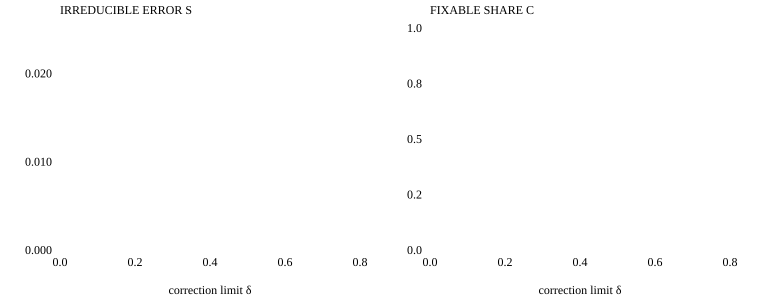

In [4]:
charts.capacity(capacity_curve(y, prior, np.round(np.arange(0, 0.82, 0.02), 2)))

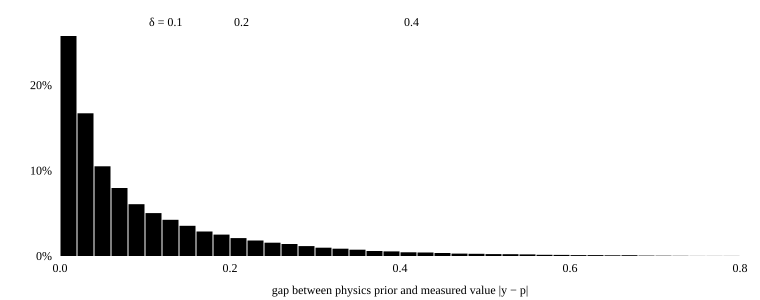

In [5]:
charts.gap(gap_distribution(y, prior))

## 2. Before deployment: the coverage-matched acceptance test

`cmat` compares a candidate with the incumbent model. It accepts only if the average error stays within the margin, enough rows change materially, more of them improve than get worse, few are harmed (with confidence), and, for a model that acts on selected rows, it beats random selection at the same coverage.

In [6]:
from hybrid_guard import cmat, random_matched
import json
meta_path = Path("data/hill_of_towie_2025_sample.json")
threshold = json.loads(meta_path.read_text())["harm_threshold"] if meta_path.exists() else 0.1316
selected = df["harm_score"].to_numpy() <= threshold
transfer, wake = df["data_model_transfer"].to_numpy(), df["physics_wake_mean"].to_numpy()
results = {
    "Retrained local model": cmat(y, df["data_model_old"], df["data_model_local"], timestamps=t),
    "Physics-features hybrid": cmat(y, df["data_model_local"], df["hybrid_physics_features"], timestamps=t),
    "Harm classifier": cmat(y, transfer, wake, selected, timestamps=t),
    "Random selection": random_matched(y, transfer, wake, selected.mean(), timestamps=t),
}
print(results["Harm classifier"].summary())

CMAT decision: REJECT
  rows 107,390, selected 7,767 (coverage 0.072), materially changed 2,108
  NRMSE 0.0743 -> 0.0743, difference -0.0001 [-0.0001, -0.0000]
  material harm 0.131 (upper 0.164), benefit 0.785, base rate 0.519
  - aggregate margin passed: NRMSE upper bound -0.0000 < 0.002
  - net benefit passed: lower bound of benefit minus harm +0.568
  - safety failed: harm upper bound 0.164 > 0.1
  - skill passed: lower bound of (base rate - harm) +0.350; better than random selection at the same coverage


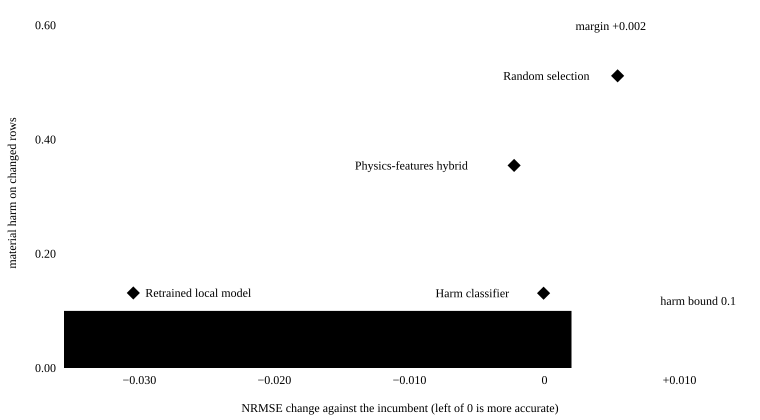

In [7]:
charts.accuracy_safety(results)

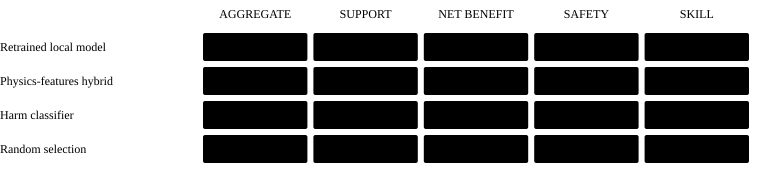

In [8]:
charts.conditions(results)

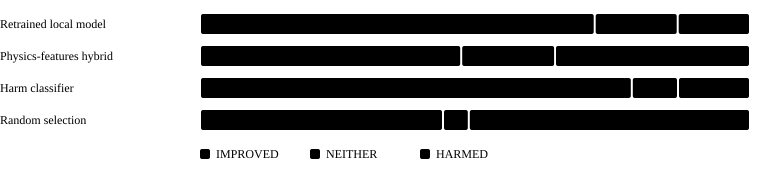

In [9]:
charts.changes(results)

In [10]:
charts.leaderboard_table(results)

#,Candidate,Verdict,NRMSE change,,Harm,,Coverage
1,Harm classifier,REJECT,−0.0001,,0.131,,0.072
2,Retrained local model,REJECT,−0.0305,,0.131,,1.000
3,Physics-features hybrid,REJECT,−0.0023,,0.354,,1.000
4,Random selection,REJECT,+0.0054,,0.511,,0.072


On this three-turbine sample the harm classifier is rejected: its harm upper bound is above 0.10. On the full 21-turbine farm the paper reports an acceptance. A smaller sample gives wider bounds, and CMAT does not certify what the evidence cannot support.

## 3. Choosing a threshold and finding where a model fails

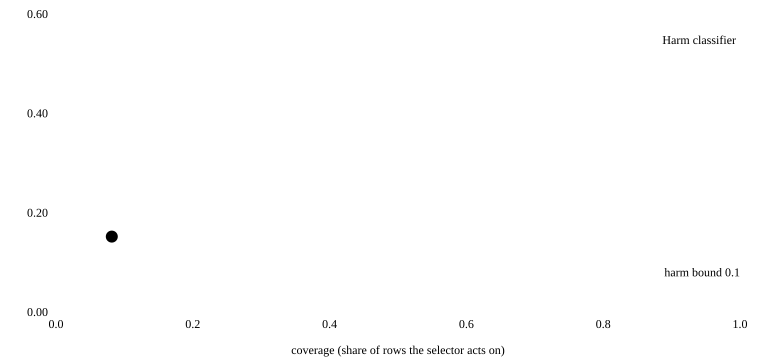

In [11]:
from hybrid_guard import coverage_harm_curve, choose_threshold
curve = coverage_harm_curve(y, transfer, wake, df["harm_score"])
charts.coverage_harm({"Harm classifier": curve}, chosen={"Harm classifier": selected.mean()})

In [12]:
pick = choose_threshold(y, transfer, wake, df["harm_score"], timestamps=t, safety_margin=0.03)
print(pick["reason"], "->", pick["threshold"])

no threshold accepted with harm upper bound at most 0.070 -> None


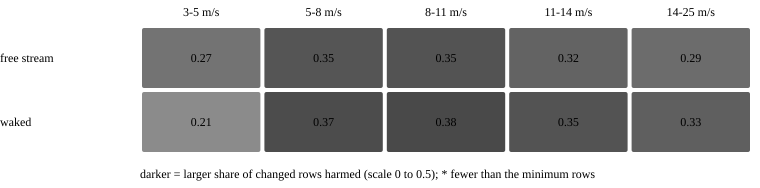

In [13]:
from hybrid_guard import bands, harm_by_condition
wake_state = np.where(df["waked"] == 1, "waked", "free stream")
table = harm_by_condition(y, df["data_model_local"], df["hybrid_physics_features"],
                          rows=wake_state, columns=bands(df["wind_speed"], [3, 5, 8, 11, 14, 25], " m/s"))
charts.harm_map(table, row_order=["free stream", "waked"],
                column_order=["3-5 m/s", "5-8 m/s", "8-11 m/s", "11-14 m/s", "14-25 m/s"])

## 4. After deployment: watch it month by month

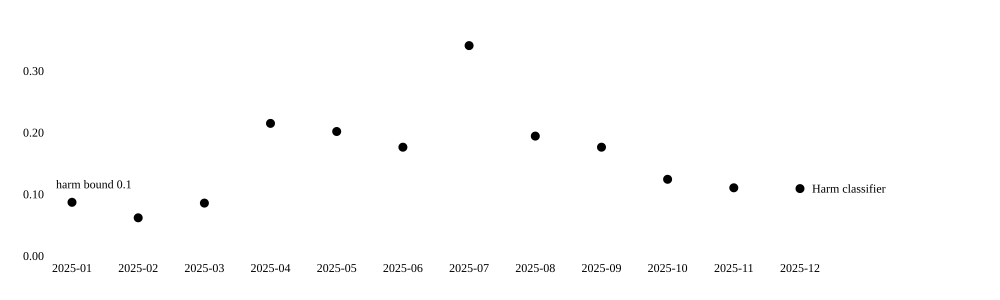

In [14]:
from hybrid_guard import monitor
watch = monitor(y, transfer, wake, selected, timestamps=t)
charts.monitor_chart({"Harm classifier": watch})

## 5. One report with everything

In [15]:
from hybrid_guard import save_report
save_report("hill_of_towie_report.html", results, title="Hill of Towie 2025 (sample)",
            charts=["accuracy_safety", "conditions", "changes", "leaderboard"],
            extra=[charts.monitor_chart({"Harm classifier": watch}), charts.harm_map(table)])

WindowsPath('hill_of_towie_report.html')

## Cite

If you use the capacity diagnostics, cite the correction-capacity paper; if you use CMAT, cite the acceptance-test paper. Both are listed in the [README](https://github.com/ahmed-ibrahim-asl/hybrid-guard#how-to-cite).